This notebook analyses the data that was formated in MARS

In [1]:
import glob
import polars as pl
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow

## Mean pitch

In [2]:
#This data is already collapsed, is not the time series
al_data_df = pd.read_csv("../data/audio_data/collapsed_pitch_from_server_v3.csv")

## Exclude recordings with too little voiced speech

Some recordings in the server CSV contain only a few seconds of voiced speech, so their mean and SD are unreliable (and they run high, mostly in misaligned cells).
We count the voiced frames in each recording's dry per-frame file (`talking == 1` and a valid f0, 5 ms frames) and keep recordings with at least 1000 voiced frames (5 s).
`st_mean` (semitones relative to the speaker's pooled median) is added as a speaker-normalised mean.
The table is saved to `../data/audio_data/collapsed_pitch_with_voiced_frames_v3.csv`, which `R_scripts/audio_stats.R` reads.

In [3]:
import re
MIN_VOICED = 1000  # 5 ms frames -> 5 s of voiced speech

rows = []
for f in sorted(glob.glob("../data/audio_data/prolific_v3/*-dry.csv")):
    m = re.search(r"-s-(.+?)-n-\d+-(p\d+p\d+)-u-(p\d+)-c-\d+-dry$", os.path.basename(f)[:-4])
    d = pl.read_csv(f, columns=["f0", "talking"], schema_overrides={"f0": pl.Float64, "talking": pl.Float64})
    f0 = d.filter((pl.col("talking") == 1) & pl.col("f0").is_not_null())["f0"].to_numpy()
    rows.append(dict(sid=m[1], dyad=m[2], user_id=m[1] + m[3], f0s=f0))
frames = pd.DataFrame(rows)

# semitones relative to each speaker's median over all their recordings
spk_median = frames.groupby("user_id").f0s.apply(lambda x: np.median(np.concatenate(list(x))))
frames["n_voiced"] = frames.f0s.apply(len)
frames["st_mean"] = [np.mean(12 * np.log2(x / spk_median[u])) if len(x) else np.nan
                     for x, u in zip(frames.f0s, frames.user_id)]

al_data_df = al_data_df.drop(columns="Unnamed: 0").merge(frames.drop(columns="f0s"), on=["sid", "dyad", "user_id"], how="left")
al_data_df.to_csv("../data/audio_data/collapsed_pitch_with_voiced_frames_v3.csv", index=False)

al_data_clean = al_data_df[al_data_df.n_voiced >= MIN_VOICED].reset_index(drop=True)
print(len(al_data_df), "recordings,", al_data_df.f0_mean.isna().sum(), "without pitch,",
      (al_data_df.n_voiced < MIN_VOICED).sum(), "with < 5 s of voiced speech ->", len(al_data_clean), "kept,",
      al_data_clean.user_id.nunique(), "participants")
al_data_df[al_data_df.n_voiced < MIN_VOICED][["user_id", "participant_condition", "other_condition", "n_voiced", "f0_mean", "f0_std"]]

177 recordings, 0 without pitch, 3 with < 5 s of voiced speech -> 174 kept, 57 participants


/Users/arias/miniforge3/envs/stim39/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/arias/miniforge3/envs/stim39/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,user_id,participant_condition,other_condition,n_voiced,f0_mean,f0_std
10,mkprolific_participant_real_32p6,U,S,874,200.196659,46.710921
54,mkprolific_participant_real_32p6,S,U,187,137.406765,50.815102
73,mkreal_meeting_experiment_prolific5p5,U,S,29,259.302097,87.015134


## Plot
Recordings with at least 5 s of voiced speech.

/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_49550/2212316964.py:1: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="st_mean", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_49550/2212316964.py:1: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="st_mean", units="user_id"


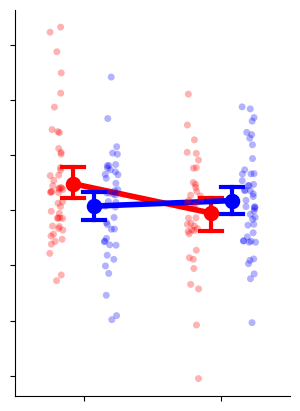

In [4]:
g = sns.catplot( x="participant_condition", y="st_mean", units="user_id"
                    , height=4.6
                    , aspect=0.8
                    , data=al_data_clean
                    , kind="point"
                    , capsize=.16
                    , hue="other_condition"
                    , legend=False
                    , scale=1.5
                    , dodge= 0.15
                    , errwidth=3
                    , order=["S", "U"]
                    , hue_order=["S", "U"]
                    , palette= sns.color_palette(["red", "blue"])
            )

# Add individual measure points
sns.stripplot(x="participant_condition", y="st_mean"
                , data=al_data_clean
                , hue="other_condition", dodge=0.15, size=5, alpha=0.3
                , legend=False
                , order=["S", "U"]
                , hue_order=["S", "U"]
                , palette= sns.color_palette(["red", "blue"])
                )    
    
#g.set(ylim=(0, 1.7))

plt.savefig("plots/mean_pitch_legend.pdf", bbox_inches='tight')
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/mean_pitch.pdf", bbox_inches='tight')

## STD

/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_49550/202838930.py:3: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="f0_std", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_49550/202838930.py:3: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="f0_std", units="user_id"


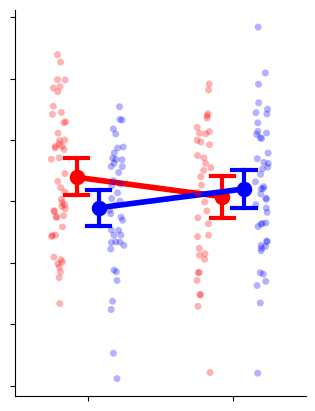

In [5]:
# STANDARD DEVIATION

g = sns.catplot( x="participant_condition", y="f0_std", units="user_id"
                    , height=4.6
                    , aspect=0.8
                    , data=al_data_clean
                    , kind="point"
                    , capsize=.16
                    , hue="other_condition"
                    , legend=False
                    , scale=1.5
                    , dodge= 0.15
                    , errwidth=3
                    , order=["S", "U"]
                    , hue_order=["S", "U"]
                    , palette= sns.color_palette(["red", "blue"])
            )

# Add individual measure points
sns.stripplot(x="participant_condition"
                , y="f0_std"
                , data=al_data_clean
                , hue="other_condition", dodge=0.15, size=5, alpha=0.3
                , legend=False
                , order=["S", "U"]
                , hue_order=["S", "U"]
                , palette= sns.color_palette(["red", "blue"])
                )    
    
#g.set(ylim=(0, 1.7))

plt.savefig("plots/std_pitch_legend.pdf", bbox_inches='tight')
g.set(xticklabels=[], yticklabels=[], title='', xlabel=None, ylabel=None)
plt.savefig("plots/std_pitch.pdf", bbox_inches='tight')

## Statistics

Same models as `R_scripts/audio_stats.R`: linear mixed models with crossed random intercepts for participant and partner, fitted with ML, and compared with likelihood-ratio tests.
* **participant condition**: `y ~ 1` vs `y ~ participant_condition`
* **other condition**: `y ~ 1` vs `y ~ other_condition`
* **interaction**: `y ~ participant_condition + other_condition` vs `y ~ participant_condition * other_condition` (1 df)
* `anova(v0, v3)` in the R script, `y ~ participant_condition` vs the full model (2 df, other condition + interaction together), is reported as `lrt_v0_v3`.

Simple contrasts come from the full model: SS − SU (smiling participant, partner smiling vs not) and UU − US (non-smiling participant, partner not smiling vs smiling).

In [6]:
import statsmodels.formula.api as smf
from scipy import stats
import warnings

def fit(formula, d):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return smf.mixedlm(formula, d, groups=np.ones(len(d)),
                           vc_formula={"u": "0 + C(user_id)", "o": "0 + C(other_id)"}).fit(reml=False)

def lrt(m_small, m_big, k):
    chi2 = 2 * (m_big.llf - m_small.llf)
    return chi2, stats.chi2.sf(chi2, k)

def pitch_stats(df, y):
    d = df.dropna(subset=[y]).copy()
    d["_y"], d["pS"], d["oS"] = d[y], (d.participant_condition == "S") * 1, (d.other_condition == "S") * 1
    nul, v0, v1 = fit("_y ~ 1", d), fit("_y ~ pS", d), fit("_y ~ oS", d)
    v2, v3 = fit("_y ~ pS + oS", d), fit("_y ~ pS * oS", d)
    names = ["oS", "pS:oS"]
    c = np.array([1, 1])
    ss_su = c @ v3.fe_params[names].values
    se_ss_su = np.sqrt(c @ v3.cov_params().loc[names, names].values @ c)
    out = dict(n=len(d))
    for lab, (a, b, k) in dict(participant=(nul, v0, 1), other=(nul, v1, 1), interaction=(v2, v3, 1), lrt_v0_v3=(v0, v3, 2)).items():
        out[lab + "_chi2"], out[lab + "_p"] = lrt(a, b, k)
    out.update(interaction_est=v3.params["pS:oS"],
               SS_SU=ss_su, SS_SU_p=2 * stats.norm.sf(abs(ss_su / se_ss_su)),
               UU_US=-v3.params["oS"], UU_US_p=v3.pvalues["oS"])
    return pd.Series(out)

measures = ["f0_mean", "f0_std", "st_mean"]
res = pd.concat({"all recordings": pd.DataFrame({y: pitch_stats(al_data_df, y) for y in measures}).T,
                 ">= 5 s voiced": pd.DataFrame({y: pitch_stats(al_data_clean, y) for y in measures}).T})
res.round(4)

n  participant_chi2  participant_p  other_chi2  \
all recordings f0_mean  177.0            0.7938         0.3730      2.4387   
               f0_std   177.0            0.0669         0.7959      1.8406   
               st_mean  177.0            0.7226         0.3953      1.4551   
>= 5 s voiced  f0_mean  174.0            2.2982         0.1295      2.7648   
               f0_std   174.0            0.0250         0.8744      1.7210   
               st_mean  174.0            2.7254         0.0988      1.4551   

                        other_p  interaction_chi2  interaction_p  \
all recordings f0_mean   0.1184            5.9009         0.0151   
               f0_std    0.1749            8.4218         0.0037   
               st_mean   0.2277            5.6467         0.0175   
>= 5 s voiced  f0_mean   0.0964            5.1464         0.0233   
               f0_std    0.1896            8.3187         0.0039   
               st_mean   0.2277            5.7390         0.0166   

                        lrt_v0_v3_chi2  lrt_v0_v3_p  interaction_est   SS_SU  \
all recordings f0_mean          8.2127       0.0165           9.0324  7.1834   
               f0_std          10.3129       0.0058           5.7348  4.1214   
               st_mean          6.9879       0.0304           0.7628  0.5572   
>= 5 s voiced  f0_mean          7.5814       0.0226           7.0249  5.7626   
               f0_std          10.0820       0.0065           5.6718  4.0351   
               st_mean          6.9465       0.0310           0.6146  0.4402   

                        SS_SU_p   UU_US  UU_US_p  
all recordings f0_mean   0.0049  1.8490   0.4832  
               f0_std    0.0021  1.6134   0.2422  
               st_mean   0.0122  0.2056   0.3684  
>= 5 s voiced  f0_mean   0.0055  1.2623   0.5627  
               f0_std    0.0025  1.6367   0.2343  
               st_mean   0.0114  0.1744   0.3402

In [7]:
# cell means (recordings with >= 5 s of voiced speech)
al_data_clean.groupby(["participant_condition", "other_condition"])[measures].agg(["mean", "sem"]).round(3)

f0_mean         f0_std        st_mean  \
                                          mean    sem    mean    sem    mean   
participant_condition other_condition                                          
S                     S                207.725  4.779  53.943  1.514   0.478   
                      U                200.975  5.421  48.965  1.549   0.074   
U                     S                200.080  6.060  50.779  1.815  -0.051   
                      U                203.500  5.036  52.044  1.619   0.174   

                                              
                                         sem  
participant_condition other_condition         
S                     S                0.151  
                      U                0.139  
U                     S                0.158  
                      U                0.128

### Results (recordings with ≥ 5 s of voiced speech: 180 recordings, 56 participants)

| | participant condition | other condition | **interaction** (1 df) | SS − SU | UU − US |
|---|---|---|---|---|---|
| f0_mean (Hz) | χ²(1) = 2.88, p = .090 | χ²(1) = 3.54, p = .060 | **χ²(1) = 10.02, p = .0016** (b = 9.9 Hz) | +7.6 Hz, p = .0003 | +2.3 Hz, p = .30 |
| f0_std (Hz) | χ²(1) = 0.22, p = .64 | χ²(1) = 2.45, p = .12 | **χ²(1) = 11.32, p = .0008** (b = 6.4 Hz) | +4.6 Hz, p = .0004 | +1.8 Hz, p = .17 |
| st_mean (st) | χ²(1) = 1.89, p = .17 | χ²(1) = 1.70, p = .19 | **χ²(1) = 11.08, p = .0009** (b = 0.90 st) | +0.61 st, p = .0008 | +0.29 st, p = .13 |

No main effects. Pitch is higher and more variable when the two partners' smile conditions match: a crossover interaction, carried mainly by smiling participants (SS > SU).
Without the exclusion (all recordings, as in the original server summary), the interaction holds for f0_std (p = .010) but not for f0_mean (p = .11): a few recordings with only a few seconds of voiced speech have high, unreliable means and mask it.
The same numbers come out of `R_scripts/audio_stats.R` (lme4).